# Multi-Modality Species Detection Heatmaps

This notebook generates detection heatmaps for three different data modalities:
1. **Drone Videos** - Frame-by-frame animal detection from aerial footage (Père David's Deer)
2. **Bioacoustic Data** - Audio recordings with bird species identification
3. **Camera Trap Photos** - Static image-based wildlife detection

Each heatmap visualizes detection patterns across time dimensions.

In [1]:
# Required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import glob
import os
import warnings
warnings.filterwarnings('ignore')

# Set style for publication-quality plots
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 12

## 1. Load and Explore Data

In [2]:
# Load drone telemetry data
drone_df = pd.read_csv('20250703_parrotanafi_1_telemetry_data.csv')
print("DRONE VIDEO DATA")
print(f"Shape: {drone_df.shape}")
print(f"\nColumns: {drone_df.columns.tolist()}")
print(f"\nDate range: {drone_df['date_time'].min()} to {drone_df['date_time'].max()}")
print(f"\nTotal animals detected: {drone_df['num_animals'].sum()}")
print(f"Frames with detections: {(drone_df['num_animals'] > 0).sum()}")
drone_df.head()

DRONE VIDEO DATA
Shape: (1637, 7)

Columns: ['filename', 'num_animals', 'latitude', 'longitude', 'file_path', 'date_time', 'species_detected/pere_david_deer']

Date range: 2025-07-01T08:34:38 to 2025-07-01T08:40:18.500000

Total animals detected: 18094
Frames with detections: 1256


,filename,num_animals,latitude,longitude,file_path,date_time,species_detected/pere_david_deer
0,VID_002_000000,0,39.82887,-81.742379,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:38,NaN
1,VID_002_000015,0,39.82887,-81.742379,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:38.500000,NaN
2,VID_002_000030,0,39.82887,-81.742380,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:39,NaN
3,VID_002_000045,0,39.82887,-81.742380,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:39.500000,NaN
4,VID_002_000060,0,39.82887,-81.742380,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:40,NaN


In [4]:
# Load bioacoustic data - Sunrise/Sunset and Every Hour recordings

# Load Sunrise/Sunset recordings (dawn & dusk)
bird_ss_df = pd.read_csv('WildsBird_Sunrise_Sunset.csv')
bird_ss_df['datetime'] = pd.to_datetime(bird_ss_df['datetime'], format='%d-%m-%Y %H:%M')


print(" BIOACOUSTIC DATA - SUNRISE/SUNSET ")

print(f"Shape: {bird_ss_df.shape}")
print(f"Locations: {bird_ss_df['location'].unique().tolist()}")
print(f"Date range: {bird_ss_df['datetime'].min().date()} to {bird_ss_df['datetime'].max().date()}")
print(f"Total bird detections: {bird_ss_df['total_birds'].sum():,}")

# Load Every Hour recordings (filtered to August only)
bird_eh_raw = pd.read_csv('WildsBird_Every_Hour.csv')
bird_eh_raw['datetime'] = pd.to_datetime(bird_eh_raw['datetime'], format='%d-%m-%Y %H:%M')
bird_eh_df = bird_eh_raw[bird_eh_raw['datetime'].dt.month == 8].copy()


print(" BIOACOUSTIC DATA - EVERY HOUR ")

print(f"Shape: {bird_eh_df.shape}")
print(f"Locations: {bird_eh_df['location'].unique().tolist()}")
print(f"Date range: {bird_eh_df['datetime'].min().date()} to {bird_eh_df['datetime'].max().date()}")
print(f"Total bird detections: {bird_eh_df['total_birds'].sum():,}")

bird_ss_df.head()


 BIOACOUSTIC DATA - SUNRISE/SUNSET 
Shape: (534, 124)
Locations: ['TW05', 'TW08']
Date range: 2025-08-04 to 2025-08-28
Total bird detections: 33,012
 BIOACOUSTIC DATA - EVERY HOUR 
Shape: (1036, 109)
Locations: ['TW08', 'TW06']
Date range: 2025-08-04 to 2025-08-28
Total bird detections: 52,810


,datetime,location,file_ID,American_Crow,American_Goldfinch,American_Kestrel,American_Robin,Bald_Eagle,Baltimore_Oriole,Bank_Swallow,...,Willow_Flycatcher,Wood_Duck,Yellow_Warbler,Yellow-bellied_Flycatcher,Yellow-bellied_Sapsucker,Yellow-billed_Cuckoo,Yellow-breasted_Chat,Yellow-throated_Vireo,Yellow-throated_Warbler,total_birds
0,2025-08-24 07:48:00,TW05,SM01_20250824_074802,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,664
1,2025-08-09 06:33:00,TW05,SM06_20250809_063302,2,31,0,0,4,0,0,...,1,0,0,0,0,5,0,0,0,551
2,2025-08-05 19:36:00,TW05,SM06_20250805_193600,0,5,0,1,0,2,0,...,0,0,0,0,0,5,5,0,0,505
3,2025-08-20 06:44:00,TW05,SM06_20250820_064402,35,12,0,0,0,0,0,...,0,1,0,0,0,2,0,0,0,504
4,2025-08-24 06:48:00,TW05,SM01_20250824_064800,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,499


In [6]:
# Get species columns and top species for each dataset

def get_top_species(df, n=15):
    """Extract top N species by total detections."""
    meta_cols = ['datetime', 'location', 'file_ID', 'total_birds', '1', 'date', 'hour', 'date_str', 'period']
    species_cols = [c for c in df.columns if c not in meta_cols]
    totals = {}
    for sp in species_cols:
        try:
            total = pd.to_numeric(df[sp], errors='coerce').sum()
            if total > 0:
                totals[sp] = total
        except:
            pass
    sorted_species = sorted(totals.keys(), key=lambda x: totals[x], reverse=True)[:n]
    return sorted_species, totals

# Sunrise/Sunset top species
top_species_ss, totals_ss = get_top_species(bird_ss_df, 15)
print("Top 10 Species (Sunrise/Sunset):")
for i, sp in enumerate(top_species_ss[:10], 1):
    print(f"  {i:2d}. {sp.replace('_', ' ')}: {int(totals_ss[sp]):,} detections")

# Every Hour top species
top_species_eh, totals_eh = get_top_species(bird_eh_df, 15)
print(f"\n Top 10 Species (Every Hour):")
for i, sp in enumerate(top_species_eh[:10], 1):
    print(f"  {i:2d}. {sp.replace('_', ' ')}: {int(totals_eh[sp]):,} detections")


Top 10 Species (Sunrise/Sunset):
   1. Mourning Dove: 8,682 detections
   2. Canada Goose: 5,318 detections
   3. Belted Kingfisher: 4,101 detections
   4. Song Sparrow: 1,532 detections
   5. Indigo Bunting: 1,408 detections
   6. Red-headed Woodpecker: 1,264 detections
   7. Purple Martin: 1,199 detections
   8. Killdeer: 982 detections
   9. American Goldfinch: 905 detections
  10. American Crow: 833 detections

 Top 10 Species (Every Hour):
   1. Grasshopper Sparrow: 19,294 detections
   2. Canada Goose: 9,677 detections
   3. Killdeer: 7,010 detections
   4. Northern Bobwhite: 3,055 detections
   5. Barred Owl: 2,922 detections
   6. Yellow-billed Cuckoo: 1,755 detections
   7. Blue Grosbeak: 1,484 detections
   8. Great Blue Heron: 1,198 detections
   9. Mourning Dove: 1,051 detections
  10. American Goldfinch: 494 detections


In [7]:
# Load camera trap photo detection data
print("CAMERA TRAP PHOTO DATA")

# Load all camera trap detection files
photo_files = [
    'TW01_CT02_detections_with_gps.csv',
    'TW02_CT01_detections_with_gps.csv',
    'TW11_CT06_detections_with_gps.csv'
]

photo_dfs = []
for f in photo_files:
    if os.path.exists(f):
        df = pd.read_csv(f)
        # Extract camera trap ID from filename
        camera_id = f.replace('_detections_with_gps.csv', '')
        df['camera_id'] = camera_id
        photo_dfs.append(df)
        print(f"\n {camera_id}:")
        print(f"   Detections: {len(df)}")
        print(f"   Unique images: {df['image'].nunique()}")
        print(f"   Species: {df['bioclip_label'].unique().tolist()}")

# Combine all photo data
photo_df = pd.concat(photo_dfs, ignore_index=True)
print(f"\n{'='*60}")
print(f"COMBINED PHOTO DATA:")
print(f"Total detections: {len(photo_df)}")
print(f"Total unique images: {photo_df['image'].nunique()}")
print(f"Camera traps: {photo_df['camera_id'].unique().tolist()}")
photo_df.head()

CAMERA TRAP PHOTO DATA

 TW01_CT02:
   Detections: 1967
   Unique images: 770
   Species: ['white-tailed deer', 'deer']

 TW02_CT01:
   Detections: 1181
   Unique images: 541
   Species: ['deer', 'white-tailed deer']

 TW11_CT06:
   Detections: 479
   Unique images: 59
   Species: ['deer', 'bird', 'white-tailed deer']

COMBINED PHOTO DATA:
Total detections: 3627
Total unique images: 1370
Camera traps: ['TW01_CT02', 'TW02_CT01', 'TW11_CT06']


,image,image_path,timestamp_file,detection_index,bioclip_label,bioclip_score,yolo_conf,distance_m,animal_lat,animal_lon,camera_id
0,NSCF0002_250805141303_0591.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:59:51.841391,1,white-tailed deer,0.513346,0.269112,26.448570,39.498376,-81.442449,TW01_CT02
1,NSCF0002_250805122102_0287.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:35:50.890774,1,deer,0.574475,0.560753,102.175760,39.497871,-81.441823,TW01_CT02
2,NSCF0002_250805122102_0287.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:35:50.890774,2,deer,0.614250,0.450281,103.061269,39.497912,-81.441769,TW01_CT02
3,NSCF0002_250805122102_0287.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:35:50.890774,3,deer,0.586962,0.446869,128.296670,39.497741,-81.441568,TW01_CT02
4,NSCF0002_250805122102_0287.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:35:50.890774,4,deer,0.596991,0.431315,116.024519,39.497808,-81.441682,TW01_CT02


In [8]:
# Analyze photo detection species distribution
print("\n Species Distribution in Camera Trap Photos:")
species_counts = photo_df['bioclip_label'].value_counts()
for species, count in species_counts.items():
    pct = count / len(photo_df) * 100
    print(f"  {species}: {count} detections ({pct:.1f}%)")


 Species Distribution in Camera Trap Photos:
  deer: 3087 detections (85.1%)
  white-tailed deer: 449 detections (12.4%)
  bird: 91 detections (2.5%)


## 2. Data Preprocessing

In [10]:
def preprocess_drone_data(df):
    """
    Preprocess drone telemetry data for heatmap generation.
    Creates time bins and extracts video segment IDs.
    """
    df = df.copy()

    # Parse datetime
    df['datetime'] = pd.to_datetime(df['date_time'], format='ISO8601')
    df['hour'] = df['datetime'].dt.hour
    df['minute'] = df['datetime'].dt.minute
    df['second'] = df['datetime'].dt.second

    # Create time bins (5-second intervals)
    df['time_bin'] = (df['minute'] * 60 + df['second']) // 5

    # Extract video ID
    df['video_id'] = df['filename'].str.extract(r'(VID_\d+)')[0]

    return df

def preprocess_bioacoustic_data(df):
    """
    Preprocess bioacoustic data for heatmap generation.
    Adds hour, date, and period columns.
    """
    df = df.copy()
    if 'datetime' not in df.columns or df['datetime'].dtype == 'object':
        df['datetime'] = pd.to_datetime(df['datetime'], format='%d-%m-%Y %H:%M')
    df['date'] = df['datetime'].dt.date
    df['hour'] = df['datetime'].dt.hour
    df['date_str'] = df['datetime'].dt.strftime('%b %d')
    df['period'] = df['hour'].apply(lambda x: 'Dawn' if x < 12 else 'Dusk')
    return df

def preprocess_photo_data(df):
    """
    Preprocess camera trap photo data for heatmap generation.
    Extracts datetime features and standardizes species names.
    """
    df = df.copy()

    # Parse timestamp
    df['datetime'] = pd.to_datetime(df['timestamp_file'])
    df['date'] = df['datetime'].dt.date
    df['hour'] = df['datetime'].dt.hour
    df['hour_bin'] = df['hour']

    # Standardize species names
    df['species'] = df['bioclip_label'].str.lower().str.strip()

    # Group similar species (e.g., all deer variants)
    df['species_group'] = df['species'].apply(
        lambda x: 'deer' if 'deer' in x else x
    )

    return df

# Preprocess datasets
drone_processed = preprocess_drone_data(drone_df)
bird_ss_processed = preprocess_bioacoustic_data(bird_ss_df)
bird_eh_processed = preprocess_bioacoustic_data(bird_eh_df)
photo_processed = preprocess_photo_data(photo_df)



## 3. Heatmap Generation Functions

In [11]:
def create_detection_heatmap(
    data,
    title,
    subtitle,
    x_label,
    y_label,
    cmap='Blues',
    figsize=(14, 8),
    stats_dict=None,
    annot=True,
    fmt='g',
    stats_color='#3498db',
    stats_bg='#f0f4f8'
):
    """
    Create a professional detection heatmap with statistics panel.

    Parameters:
    -----------
    data : pd.DataFrame
        Pivoted data for heatmap (index=y, columns=x, values=counts)
    title, subtitle : str
        Plot titles
    cmap : str
        Colormap name
    stats_dict : dict
        Additional statistics to display
    """

    # Create figure with GridSpec for layout
    fig = plt.figure(figsize=figsize, facecolor='white')
    gs = fig.add_gridspec(2, 2, height_ratios=[6, 1], width_ratios=[4, 0.2],
                          hspace=0.3, wspace=0.05)

    # Main heatmap axis
    ax_heatmap = fig.add_subplot(gs[0, 0])

    # Colorbar axis
    ax_cbar = fig.add_subplot(gs[0, 1])

    # Stats panel axis
    ax_stats = fig.add_subplot(gs[1, :])
    ax_stats.axis('off')

    # Determine annotation settings based on data size
    show_annot = annot and (data.shape[0] * data.shape[1] < 150)

    # Create heatmap
    sns.heatmap(
        data,
        ax=ax_heatmap,
        cmap=cmap,
        linewidths=0.5,
        linecolor='white',
        cbar_ax=ax_cbar,
        annot=show_annot,
        fmt=fmt,
        annot_kws={'size': 9, 'fontweight': 'bold'},
        square=False
    )

    # Customize heatmap
    ax_heatmap.set_xlabel(x_label, fontsize=14, fontweight='bold', labelpad=10)
    ax_heatmap.set_ylabel(y_label, fontsize=14, fontweight='bold', labelpad=10)
    ax_heatmap.tick_params(axis='x', rotation=45)
    ax_heatmap.tick_params(axis='y', rotation=0)

    # Title
    fig.suptitle(f'{title}', fontsize=20, fontweight='bold', y=0.98)
    ax_heatmap.set_title(subtitle, fontsize=12, color='gray', pad=10)

    # Colorbar label
    ax_cbar.set_ylabel('Detection Count', fontsize=12, labelpad=10)

    # Add statistics panel
    if stats_dict:
        stats_text = "  |  ".join([f"{k}: {v}" for k, v in stats_dict.items()])
        ax_stats.text(0.5, 0.5, f" Statistics: {stats_text}",
                     transform=ax_stats.transAxes,
                     fontsize=11,
                     ha='center',
                     va='center',
                     bbox=dict(boxstyle='round,pad=0.5', facecolor=stats_bg,
                              edgecolor=stats_color, linewidth=2))

    plt.tight_layout()
    return fig

## 4. Drone Video Detection Heatmap

Visualizes Père David's Deer detections from aerial drone footage.

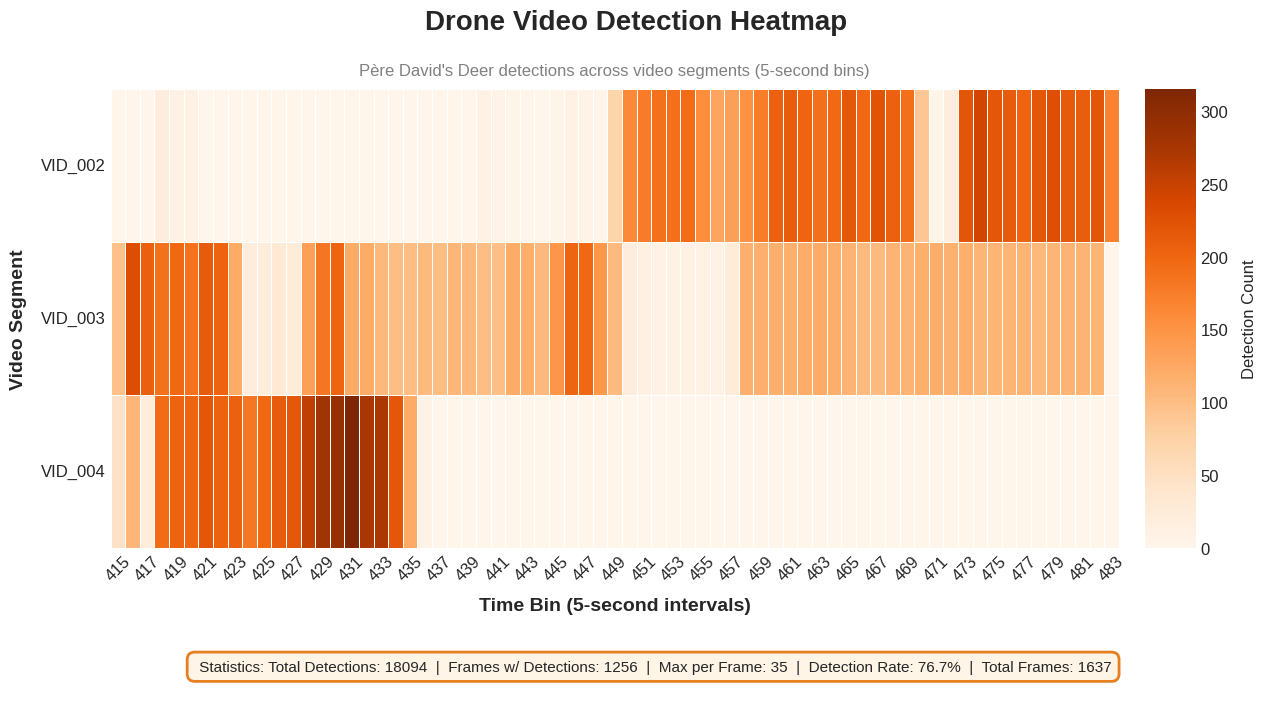


 Saved: drone_detection_heatmap.png


In [12]:
# Aggregate drone data by video and time bin
drone_agg = drone_processed.groupby(['video_id', 'time_bin'])['num_animals'].sum().reset_index()

# Pivot for heatmap
drone_pivot = drone_agg.pivot(index='video_id', columns='time_bin', values='num_animals').fillna(0)

# Calculate statistics
total_detections = drone_processed['num_animals'].sum()
frames_with_detections = (drone_processed['num_animals'] > 0).sum()
max_in_frame = drone_processed['num_animals'].max()
detection_rate = (frames_with_detections / len(drone_processed)) * 100

drone_stats = {
    'Total Detections': int(total_detections),
    'Frames w/ Detections': int(frames_with_detections),
    'Max per Frame': int(max_in_frame),
    'Detection Rate': f'{detection_rate:.1f}%',
    'Total Frames': len(drone_processed)
}

# Create heatmap
fig_drone = create_detection_heatmap(
    data=drone_pivot,
    title="Drone Video Detection Heatmap",
    subtitle="Père David's Deer detections across video segments (5-second bins)",
    x_label="Time Bin (5-second intervals)",
    y_label="Video Segment",
    cmap='Oranges',
    stats_dict=drone_stats,
    annot=False,  # Too many cells
    stats_color='#e67e22',
    stats_bg='#fef5e7'
)

plt.savefig('drone_detection_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


## 5. Bioacoustic Detection Heatmap

Visualizes bird species detected from audio recordings.

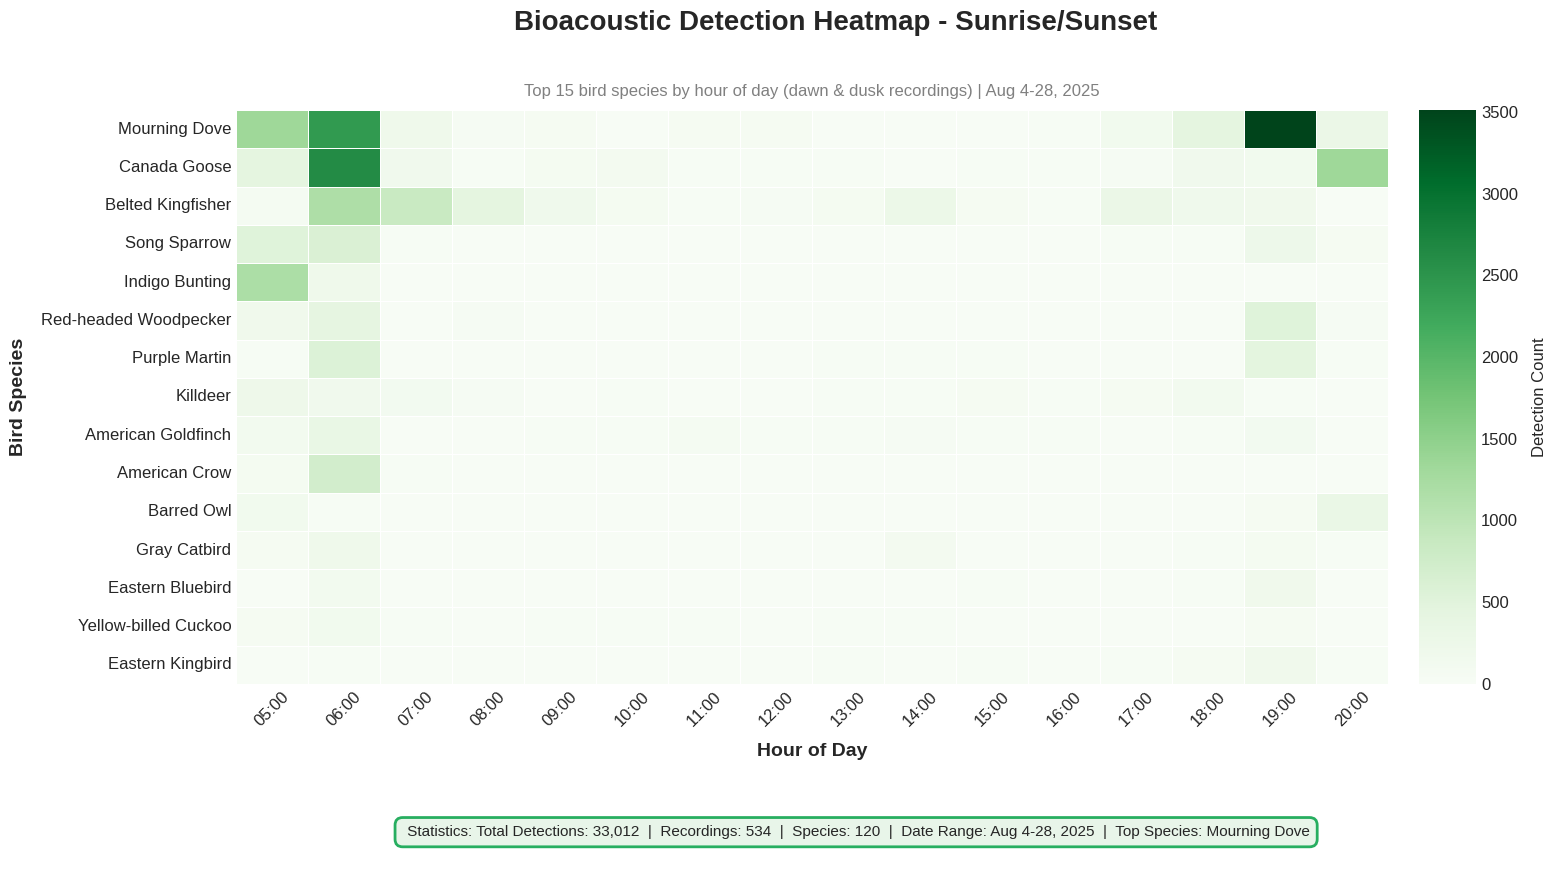

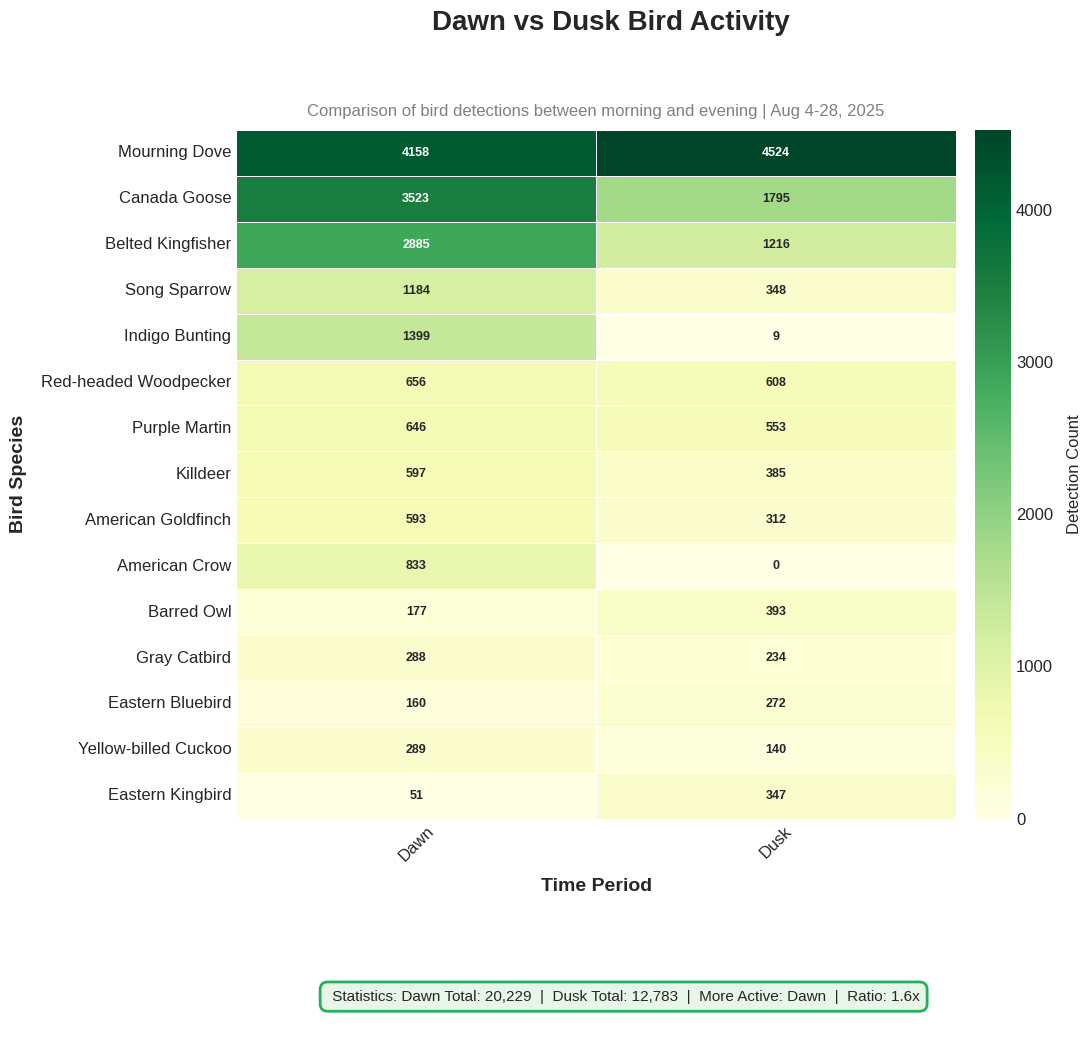

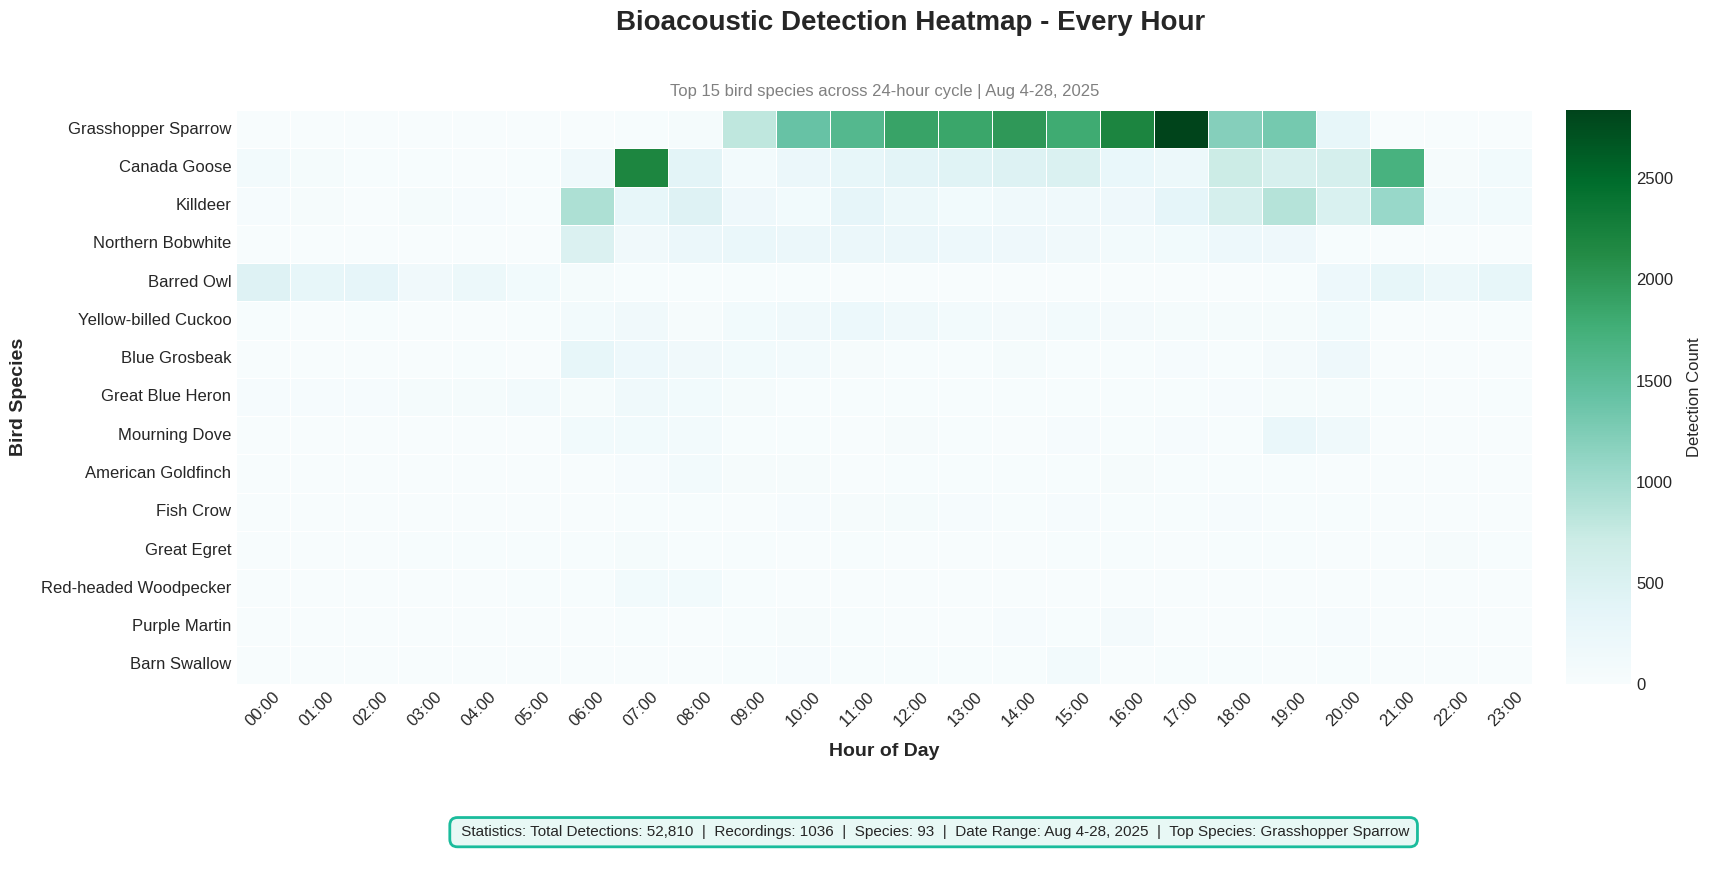

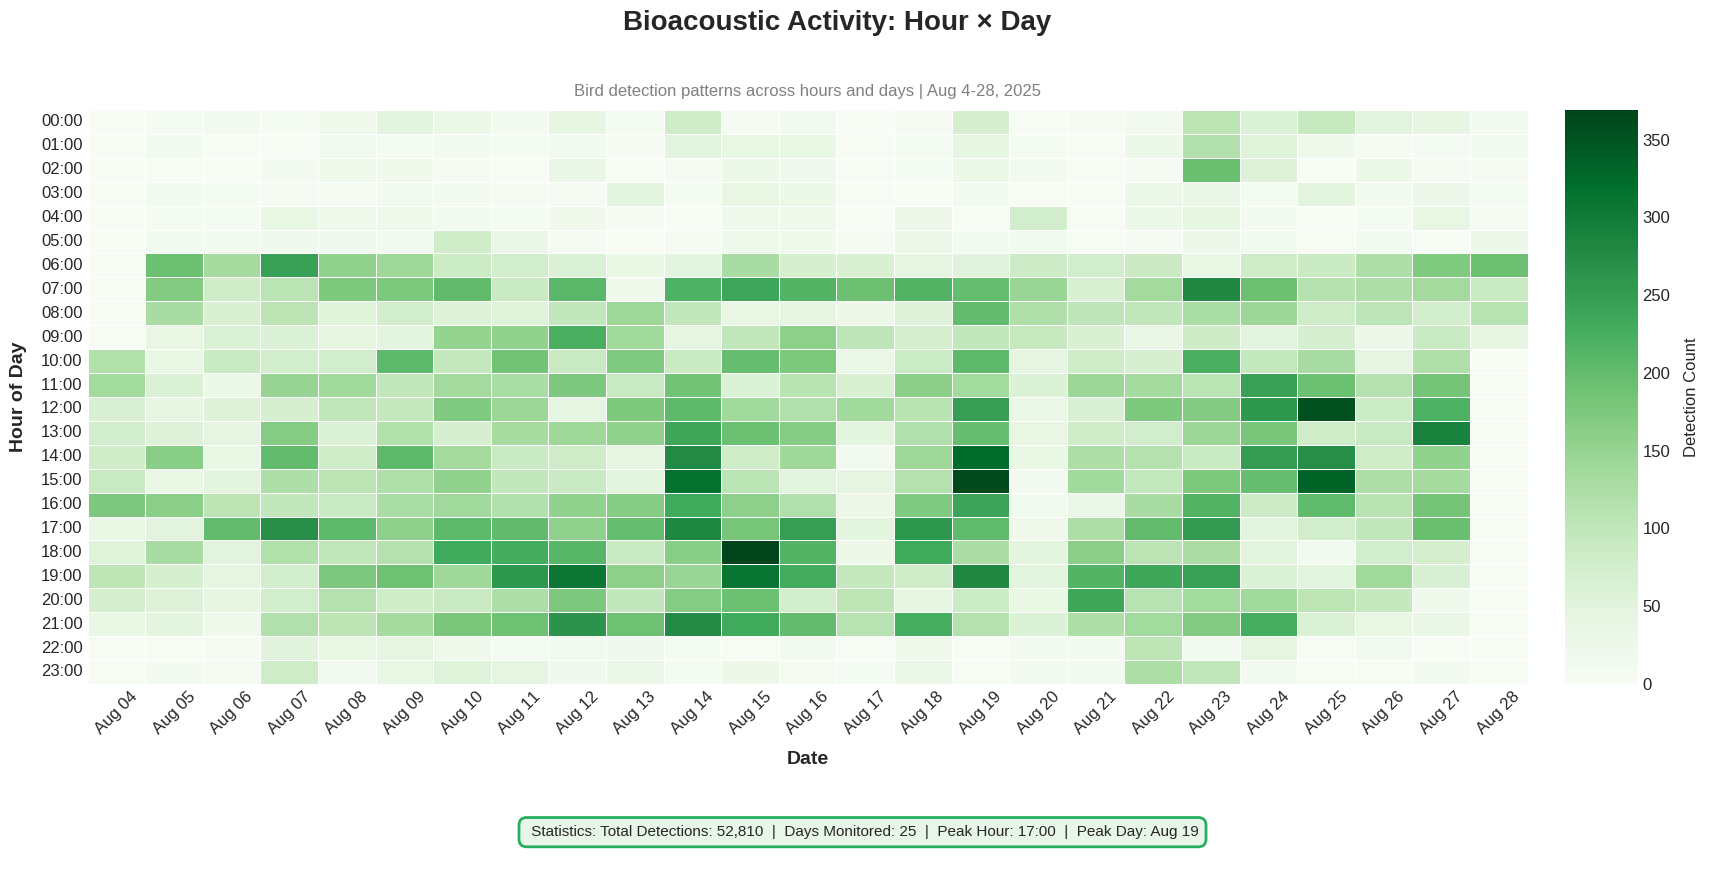

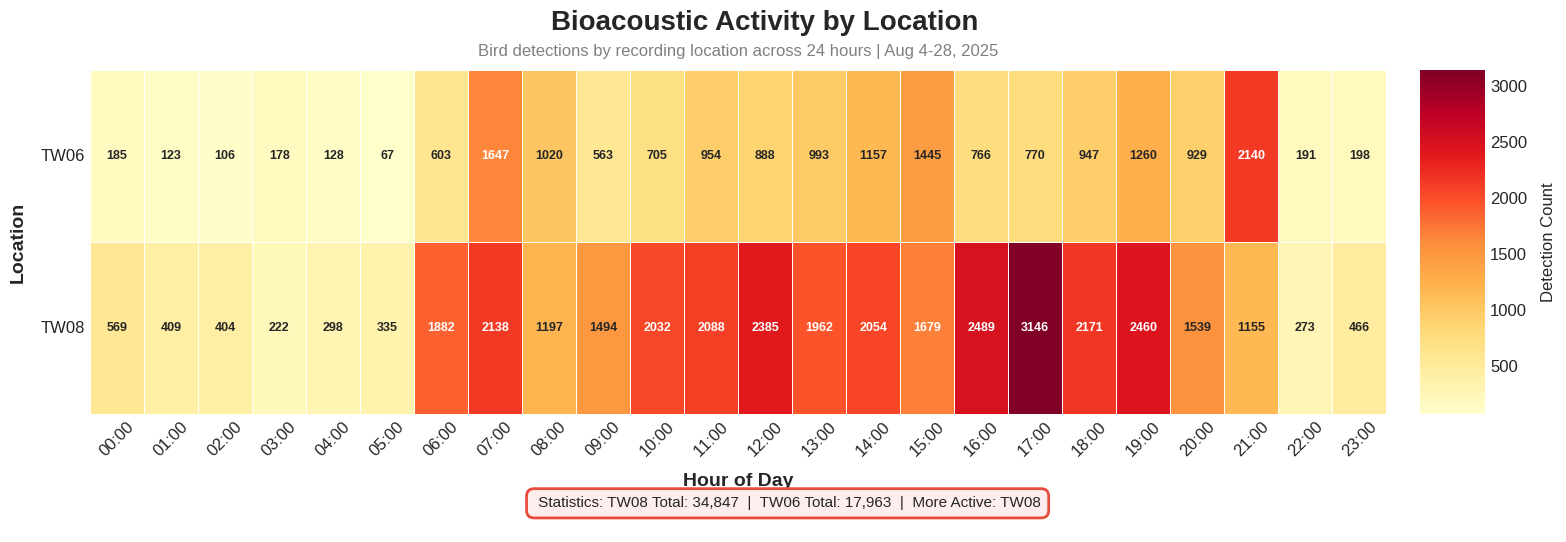

In [14]:

# Get top species for each dataset
meta_cols_ss = ['datetime', 'location', 'file_ID', 'total_birds', 'date', 'hour', 'date_str', 'period']
meta_cols_eh = ['datetime', 'location', 'file_ID', 'total_birds', '1', 'date', 'hour', 'date_str', 'period']

species_cols_ss = [c for c in bird_ss_processed.columns if c not in meta_cols_ss]
species_cols_eh = [c for c in bird_eh_processed.columns if c not in meta_cols_eh]

def get_top_n_species(df, species_cols, n=15):
    totals = {}
    for sp in species_cols:
        try:
            total = pd.to_numeric(df[sp], errors='coerce').sum()
            if total > 0:
                totals[sp] = total
        except:
            pass
    return sorted(totals.keys(), key=lambda x: totals[x], reverse=True)[:n]

top_species_ss = get_top_n_species(bird_ss_processed, species_cols_ss, 15)
top_species_eh = get_top_n_species(bird_eh_processed, species_cols_eh, 15)




species_hour_data = []
for _, row in bird_ss_processed.iterrows():
    for sp in top_species_ss:
        val = pd.to_numeric(row.get(sp, 0), errors='coerce')
        if pd.notna(val) and val > 0:
            species_hour_data.append({'species': sp.replace('_', ' '), 'hour': row['hour'], 'count': val})

species_hour_df = pd.DataFrame(species_hour_data)
species_hour_agg = species_hour_df.groupby(['species', 'hour'])['count'].sum().reset_index()
species_hour_pivot = species_hour_agg.pivot(index='species', columns='hour', values='count').fillna(0)

row_totals = species_hour_pivot.sum(axis=1)
species_hour_pivot = species_hour_pivot.loc[row_totals.sort_values(ascending=False).index]
species_hour_pivot.columns = [f'{int(h):02d}:00' for h in species_hour_pivot.columns]

ss_stats = {
    'Total Detections': f"{int(bird_ss_processed['total_birds'].sum()):,}",
    'Recordings': len(bird_ss_processed),
    'Species': len([c for c in species_cols_ss if bird_ss_processed[c].sum() > 0]),
    'Date Range': 'Aug 4-28, 2025',
    'Top Species': top_species_ss[0].replace('_', ' ')
}

fig = create_detection_heatmap(species_hour_pivot, "Bioacoustic Detection Heatmap - Sunrise/Sunset",
    "Top 15 bird species by hour of day (dawn & dusk recordings) | Aug 4-28, 2025",
    "Hour of Day", "Bird Species", cmap='Greens', figsize=(16, 10),
    stats_dict=ss_stats, annot=True, fmt='.0f', stats_color='#27ae60', stats_bg='#e8f5e9')
plt.savefig('bioacoustic_sunrise_sunset_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()





dawn_dusk_data = []
for _, row in bird_ss_processed.iterrows():
    for sp in top_species_ss:
        val = pd.to_numeric(row.get(sp, 0), errors='coerce')
        if pd.notna(val) and val > 0:
            dawn_dusk_data.append({'species': sp.replace('_', ' '), 'period': row['period'], 'count': val})

dawn_dusk_df = pd.DataFrame(dawn_dusk_data)
dawn_dusk_agg = dawn_dusk_df.groupby(['species', 'period'])['count'].sum().reset_index()
dawn_dusk_pivot = dawn_dusk_agg.pivot(index='species', columns='period', values='count').fillna(0)
dawn_dusk_pivot['Total'] = dawn_dusk_pivot.sum(axis=1)
dawn_dusk_pivot = dawn_dusk_pivot.sort_values('Total', ascending=False)[['Dawn', 'Dusk']]

dawn_total = bird_ss_processed[bird_ss_processed['period'] == 'Dawn']['total_birds'].sum()
dusk_total = bird_ss_processed[bird_ss_processed['period'] == 'Dusk']['total_birds'].sum()

dawn_dusk_stats = {
    'Dawn Total': f"{int(dawn_total):,}",
    'Dusk Total': f"{int(dusk_total):,}",
    'More Active': 'Dawn' if dawn_total > dusk_total else 'Dusk',
    'Ratio': f"{max(dawn_total, dusk_total) / max(min(dawn_total, dusk_total), 1):.1f}x"
}

fig = create_detection_heatmap(dawn_dusk_pivot, "Dawn vs Dusk Bird Activity",
    "Comparison of bird detections between morning and evening | Aug 4-28, 2025",
    "Time Period", "Bird Species", cmap='YlGn', figsize=(10, 12),
    stats_dict=dawn_dusk_stats, annot=True, fmt='.0f', stats_color='#27ae60', stats_bg='#e8f5e9')
plt.savefig('bioacoustic_dawn_dusk_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()





species_hour_eh_data = []
for _, row in bird_eh_processed.iterrows():
    for sp in top_species_eh:
        val = pd.to_numeric(row.get(sp, 0), errors='coerce')
        if pd.notna(val) and val > 0:
            species_hour_eh_data.append({'species': sp.replace('_', ' '), 'hour': row['hour'], 'count': val})

species_hour_eh_df = pd.DataFrame(species_hour_eh_data)
species_hour_eh_agg = species_hour_eh_df.groupby(['species', 'hour'])['count'].sum().reset_index()
species_hour_eh_pivot = species_hour_eh_agg.pivot(index='species', columns='hour', values='count').fillna(0)

for h in range(24):
    if h not in species_hour_eh_pivot.columns:
        species_hour_eh_pivot[h] = 0
species_hour_eh_pivot = species_hour_eh_pivot[sorted(species_hour_eh_pivot.columns)]

row_totals = species_hour_eh_pivot.sum(axis=1)
species_hour_eh_pivot = species_hour_eh_pivot.loc[row_totals.sort_values(ascending=False).index]
species_hour_eh_pivot.columns = [f'{int(h):02d}:00' for h in species_hour_eh_pivot.columns]

eh_stats = {
    'Total Detections': f"{int(bird_eh_processed['total_birds'].sum()):,}",
    'Recordings': len(bird_eh_processed),
    'Species': len([c for c in species_cols_eh if bird_eh_processed[c].sum() > 0]),
    'Date Range': 'Aug 4-28, 2025',
    'Top Species': top_species_eh[0].replace('_', ' ')
}

fig = create_detection_heatmap(species_hour_eh_pivot, "Bioacoustic Detection Heatmap - Every Hour",
    "Top 15 bird species across 24-hour cycle | Aug 4-28, 2025",
    "Hour of Day", "Bird Species", cmap='BuGn', figsize=(18, 10),
    stats_dict=eh_stats, annot=False, stats_color='#1abc9c', stats_bg='#e8f8f5')
plt.savefig('bioacoustic_every_hour_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()




hour_day_agg = bird_eh_processed.groupby(['hour', 'date_str', 'date'])['total_birds'].sum().reset_index()
date_order = hour_day_agg.drop_duplicates('date').sort_values('date')['date_str'].tolist()

hour_day_pivot = hour_day_agg.pivot(index='hour', columns='date_str', values='total_birds').fillna(0)
hour_day_pivot = hour_day_pivot[[c for c in date_order if c in hour_day_pivot.columns]]

for h in range(24):
    if h not in hour_day_pivot.index:
        hour_day_pivot.loc[h] = 0
hour_day_pivot = hour_day_pivot.sort_index()
hour_day_pivot.index = [f'{int(h):02d}:00' for h in hour_day_pivot.index]

peak_hour = bird_eh_processed.groupby('hour')['total_birds'].sum().idxmax()
peak_day = bird_eh_processed.groupby('date_str')['total_birds'].sum().idxmax()

hour_day_stats = {
    'Total Detections': f"{int(bird_eh_processed['total_birds'].sum()):,}",
    'Days Monitored': len(date_order),
    'Peak Hour': f'{int(peak_hour):02d}:00',
    'Peak Day': peak_day
}

fig = create_detection_heatmap(hour_day_pivot, "Bioacoustic Activity: Hour × Day",
    "Bird detection patterns across hours and days | Aug 4-28, 2025",
    "Date", "Hour of Day", cmap='Greens', figsize=(20, 10),
    stats_dict=hour_day_stats, annot=False, stats_color='#27ae60', stats_bg='#e8f5e9')
plt.savefig('bioacoustic_hour_day_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()




loc_hour_agg = bird_eh_processed.groupby(['location', 'hour'])['total_birds'].sum().reset_index()
loc_hour_pivot = loc_hour_agg.pivot(index='location', columns='hour', values='total_birds').fillna(0)

for h in range(24):
    if h not in loc_hour_pivot.columns:
        loc_hour_pivot[h] = 0
loc_hour_pivot = loc_hour_pivot[sorted(loc_hour_pivot.columns)]
loc_hour_pivot.columns = [f'{int(h):02d}:00' for h in loc_hour_pivot.columns]

loc_totals = bird_eh_processed.groupby('location')['total_birds'].sum()
loc_stats = {
    'TW08 Total': f"{int(loc_totals.get('TW08', 0)):,}",
    'TW06 Total': f"{int(loc_totals.get('TW06', 0)):,}",
    'More Active': loc_totals.idxmax() if len(loc_totals) > 0 else 'N/A'
}

fig = create_detection_heatmap(loc_hour_pivot, "Bioacoustic Activity by Location",
    "Bird detections by recording location across 24 hours | Aug 4-28, 2025",
    "Hour of Day", "Location", cmap='YlOrRd', figsize=(18, 6),
    stats_dict=loc_stats, annot=True, fmt='.0f', stats_color='#e74c3c', stats_bg='#fdedec')
plt.savefig('bioacoustic_location_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()




## 6. Camera Trap Photo Detection Heatmap

Visualizes wildlife detected in camera trap photographs across different locations.

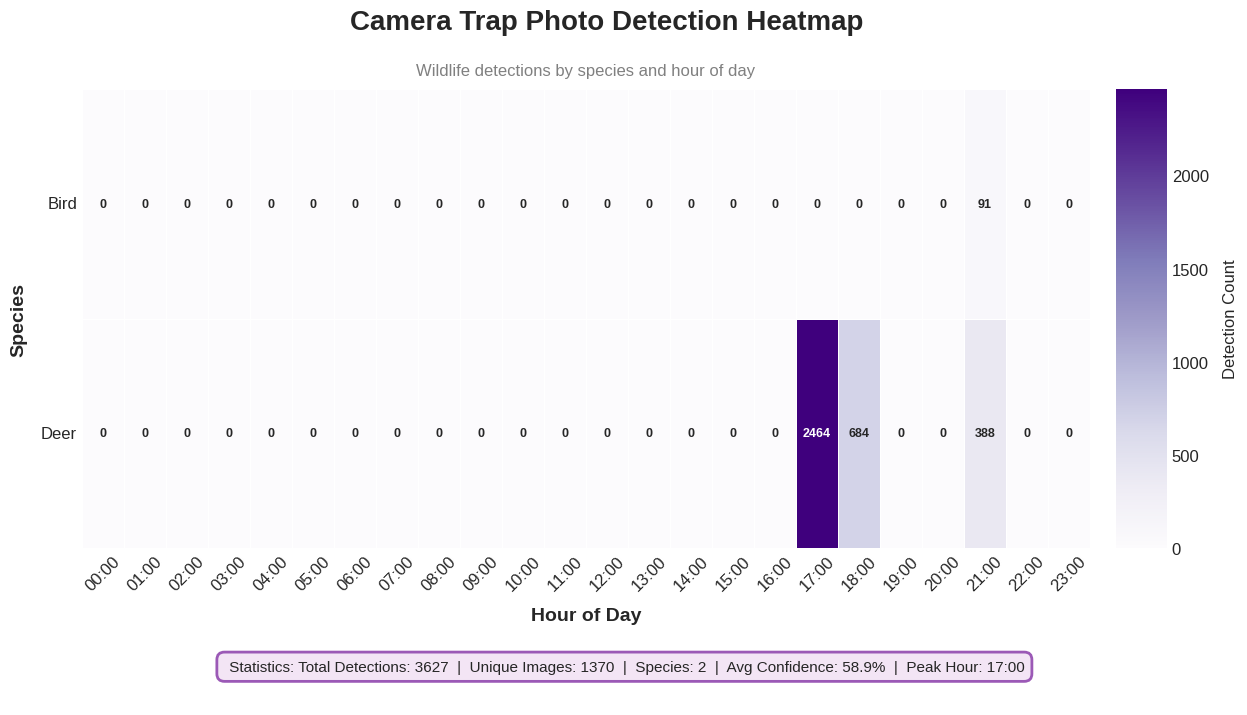


Saved: photo_detection_heatmap.png


In [15]:
# Create heatmap: Species x Hour of Day
# Count detections per species per hour
photo_species_hour = photo_processed.groupby(['species_group', 'hour_bin']).size().reset_index(name='count')

# Pivot for heatmap
photo_pivot_hour = photo_species_hour.pivot(
    index='species_group',
    columns='hour_bin',
    values='count'
).fillna(0)

# Ensure all hours are present (0-23)
all_hours = list(range(24))
for h in all_hours:
    if h not in photo_pivot_hour.columns:
        photo_pivot_hour[h] = 0
photo_pivot_hour = photo_pivot_hour[sorted(photo_pivot_hour.columns)]

# Create hour labels
hour_labels = [f'{h:02d}:00' for h in photo_pivot_hour.columns]
photo_pivot_hour.columns = hour_labels

# Capitalize species names
photo_pivot_hour.index = photo_pivot_hour.index.str.title()

# Calculate statistics
total_photo_detections = len(photo_processed)
unique_images = photo_processed['image'].nunique()
unique_species_photo = photo_processed['species_group'].nunique()
avg_confidence = photo_processed['bioclip_score'].mean()
peak_hour = photo_processed['hour_bin'].mode().iloc[0]

photo_stats = {
    'Total Detections': total_photo_detections,
    'Unique Images': unique_images,
    'Species': unique_species_photo,
    'Avg Confidence': f'{avg_confidence:.1%}',
    'Peak Hour': f'{peak_hour:02d}:00'
}

# Create heatmap
fig_photo = create_detection_heatmap(
    data=photo_pivot_hour,
    title="Camera Trap Photo Detection Heatmap",
    subtitle="Wildlife detections by species and hour of day",
    x_label="Hour of Day",
    y_label="Species",
    cmap='Purples',
    stats_dict=photo_stats,
    annot=True,
    fmt='.0f',
    stats_color='#9b59b6',
    stats_bg='#f3e5f5'
)

plt.savefig('photo_detection_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("\nSaved: photo_detection_heatmap.png")

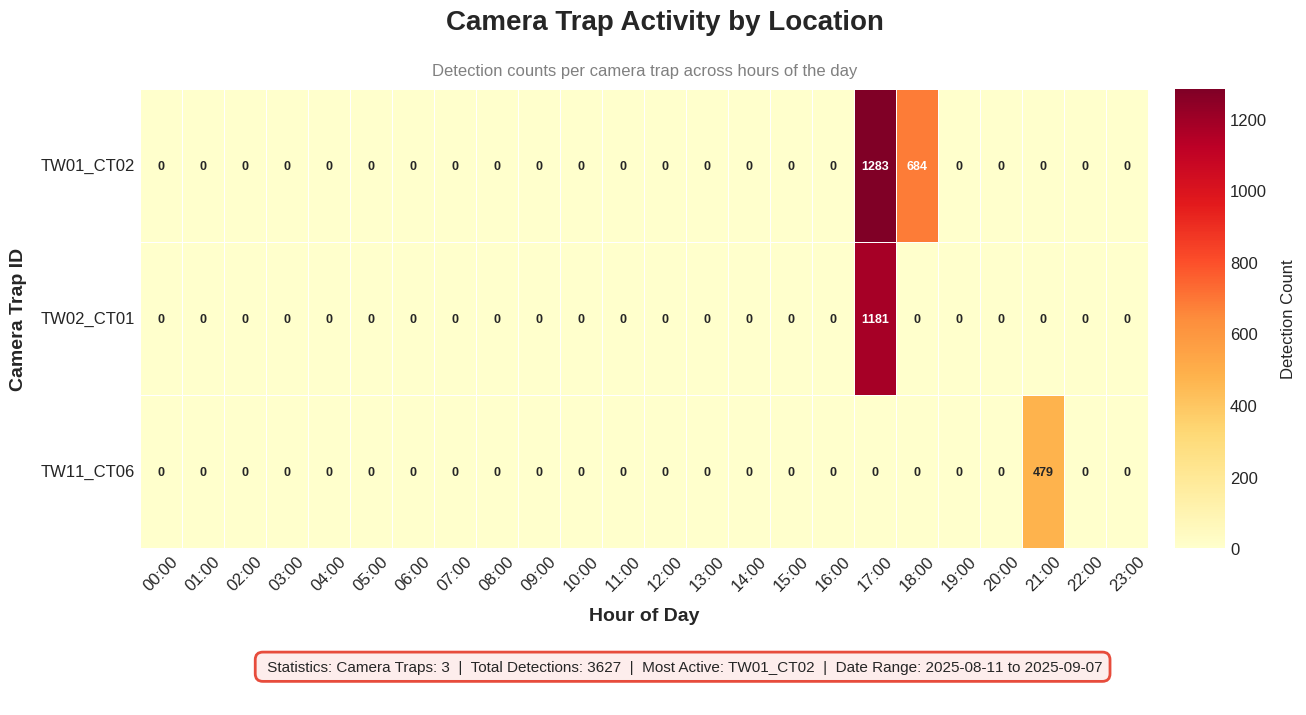


 Saved: camera_location_heatmap.png


In [16]:

photo_camera_hour = photo_processed.groupby(['camera_id', 'hour_bin']).size().reset_index(name='count')

# Pivot for heatmap
photo_pivot_camera = photo_camera_hour.pivot(
    index='camera_id',
    columns='hour_bin',
    values='count'
).fillna(0)

# Ensure all hours are present
for h in range(24):
    if h not in photo_pivot_camera.columns:
        photo_pivot_camera[h] = 0
photo_pivot_camera = photo_pivot_camera[sorted(photo_pivot_camera.columns)]

# Create hour labels
hour_labels = [f'{h:02d}:00' for h in photo_pivot_camera.columns]
photo_pivot_camera.columns = hour_labels

# Calculate camera-specific stats
camera_stats = {
    'Camera Traps': photo_processed['camera_id'].nunique(),
    'Total Detections': len(photo_processed),
    'Most Active': photo_processed['camera_id'].value_counts().idxmax(),
    'Date Range': f"{photo_processed['date'].min()} to {photo_processed['date'].max()}"
}

# Create heatmap
fig_camera = create_detection_heatmap(
    data=photo_pivot_camera,
    title="Camera Trap Activity by Location",
    subtitle="Detection counts per camera trap across hours of the day",
    x_label="Hour of Day",
    y_label="Camera Trap ID",
    cmap='YlOrRd',
    stats_dict=camera_stats,
    annot=True,
    fmt='.0f',
    stats_color='#e74c3c',
    stats_bg='#fdedec'
)

plt.savefig('camera_location_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


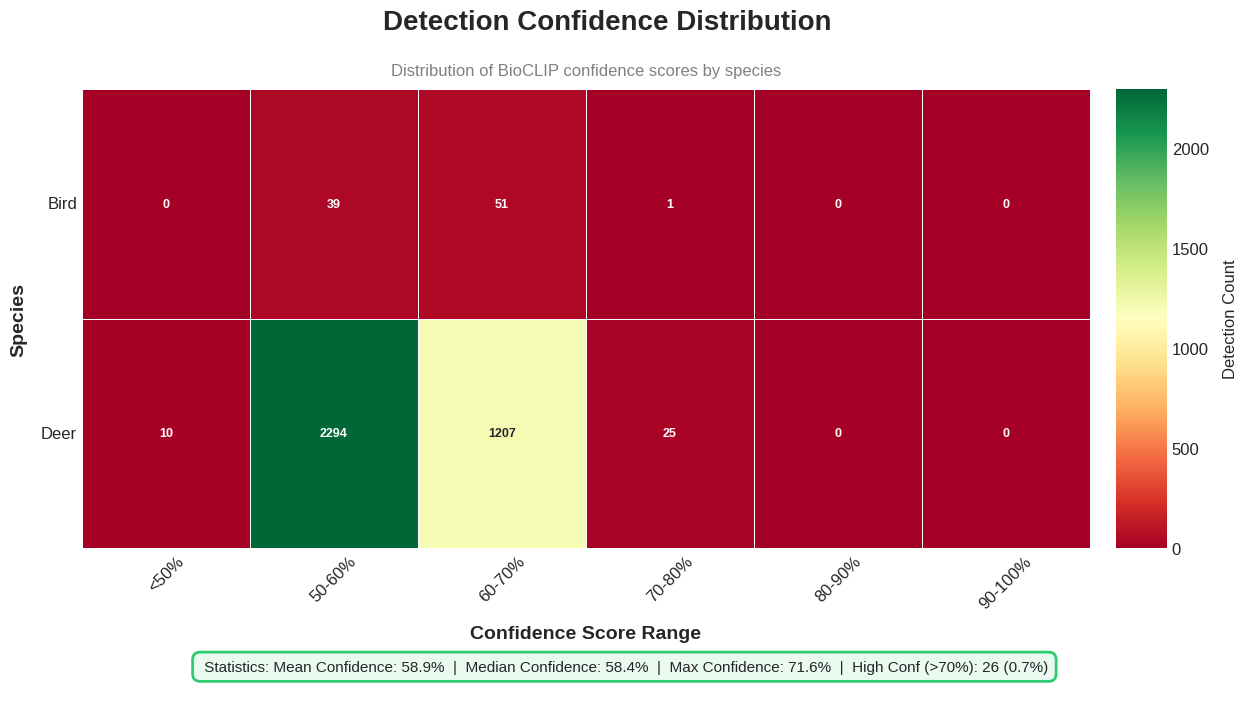


 Saved: confidence_distribution_heatmap.png


In [17]:
# Create heatmap: Confidence Score Distribution by Species
# Bin confidence scores
photo_processed['conf_bin'] = pd.cut(
    photo_processed['bioclip_score'],
    bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    labels=['<50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
)

# Count by species and confidence bin
conf_species = photo_processed.groupby(['species_group', 'conf_bin']).size().reset_index(name='count')

# Pivot
conf_pivot = conf_species.pivot(
    index='species_group',
    columns='conf_bin',
    values='count'
).fillna(0)

# Capitalize species names
conf_pivot.index = conf_pivot.index.str.title()

# Stats
conf_stats = {
    'Mean Confidence': f"{photo_processed['bioclip_score'].mean():.1%}",
    'Median Confidence': f"{photo_processed['bioclip_score'].median():.1%}",
    'Max Confidence': f"{photo_processed['bioclip_score'].max():.1%}",
    'High Conf (>70%)': f"{(photo_processed['bioclip_score'] > 0.7).sum()} ({(photo_processed['bioclip_score'] > 0.7).mean():.1%})"
}

# Create heatmap
fig_conf = create_detection_heatmap(
    data=conf_pivot,
    title="Detection Confidence Distribution",
    subtitle="Distribution of BioCLIP confidence scores by species",
    x_label="Confidence Score Range",
    y_label="Species",
    cmap='RdYlGn',
    stats_dict=conf_stats,
    annot=True,
    fmt='.0f',
    stats_color='#2ecc71',
    stats_bg='#eafaf1'
)

plt.savefig('confidence_distribution_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
